# 01 — Data collection

**Objective.** Understand how fact-checks are collected legally and reproducibly, and inspect what one collection run produced.

Sources are read through their public WordPress REST APIs after checking `robots.txt`. BOOM Live (HTTP 403) and PIB Fact Check (HTTP 401) refused automated access and were **not** bypassed.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (9, 4)
from ml.config import PROCESSED_DATASET, ARTIFACTS_DIR, METADATA_DIR, RAW_DIR


## Source registry
Each source declares its API root, language and whether posts must have a parseable verdict (Alt News mixes reporting with fact-checks).

In [2]:
from ml.data_collection.sources import SOURCES, UNAVAILABLE_SOURCES
pd.DataFrame([{**{k: getattr(s, k) for k in ('key','publisher','base_url','language','require_verdict')}} for s in SOURCES.values()])

,key,publisher,base_url,language,require_verdict
0,factly_en,Factly,https://factly.in,en,False
1,factly_kn,Factly,https://factly.in,kn,False
2,altnews_en,Alt News,https://www.altnews.in,en,True
3,altnews_hi,Alt News,https://www.altnews.in/hindi,hi,True


In [3]:
pd.DataFrame([s.__dict__ for s in UNAVAILABLE_SOURCES])

,publisher,homepage,reason,checked_on
0,BOOM Live,https://www.boomlive.in,HTTP 403 for robots.txt and RSS with an honest...,2026-11-04
1,PIB Fact Check,https://factcheck.pib.gov.in,HTTP 401 / 'URL is inaccessible'. Primary chan...,2026-11-04


## Parsing one post (offline example)
`WordPressCollector.parse_post` turns an API post into a `FactCheckRecord`. We feed it a hand-written post so the notebook runs without network access.

In [4]:
from ml.data_collection.wordpress_collector import WordPressCollector
c = WordPressCollector(SOURCES['factly_en'])
c._categories = {1: 'Politics'}
post = {'title': {'rendered': 'Old video from Bangladesh falsely shared as police firing in Delhi'}, 'link': 'https://factly.in/example/',
        'date': '2026-11-03T10:00:00', 'categories': [1], 'excerpt': {'rendered': '<p>A video is viral...</p>'},
        'content': {'rendered': '<p>Claim: Video shows Delhi Police firing at protesters. Fact: The video is from Bangladesh (2024). To sum up, an old video from Bangladesh is being shared as Delhi.</p>'}}
c.parse_post(post).to_dict()

{'claim_id': 'factly-8d46aa83183f4c80',
 'claim_text': 'Video shows Delhi Police firing at protesters.',
 'claim_source': 'claim_field',
 'fact_check_title': 'Old video from Bangladesh falsely shared as police firing in Delhi',
 'fact_check_url': 'https://factly.in/example/',
 'verdict': 'OUTDATED',
 'verdict_raw': 'Old video',
 'verdict_rule': 'en_outdated',
 'explanation': 'an old video from Bangladesh is being shared as Delhi.',
 'category': 'Politics',
 'category_source': 'publisher_tag',
 'language': 'en',
 'publisher': 'Factly',
 'publication_date': '2026-11-03',
 'collection_date': '2026-11-04T06:04:45+00:00'}

## What the real collection run produced
The collection log records pages fetched, posts kept and dropped per source.

In [5]:
runs = [json.loads(l) for l in (METADATA_DIR / 'collection_log.jsonl').read_text(encoding='utf-8').splitlines()]
pd.DataFrame([{**{'source': k}, **{x: v.get(x) for x in ('pages_fetched','posts_seen','kept','dropped_no_verdict','seconds')}} for r in runs for k, v in r['sources'].items()])

,source,pages_fetched,posts_seen,kept,dropped_no_verdict,seconds
0,factly_en,30,1500,1500,0,65.0
1,factly_kn,22,1072,1072,0,49.8
2,altnews_en,25,1250,735,515,107.0
3,altnews_hi,25,1250,831,419,109.0


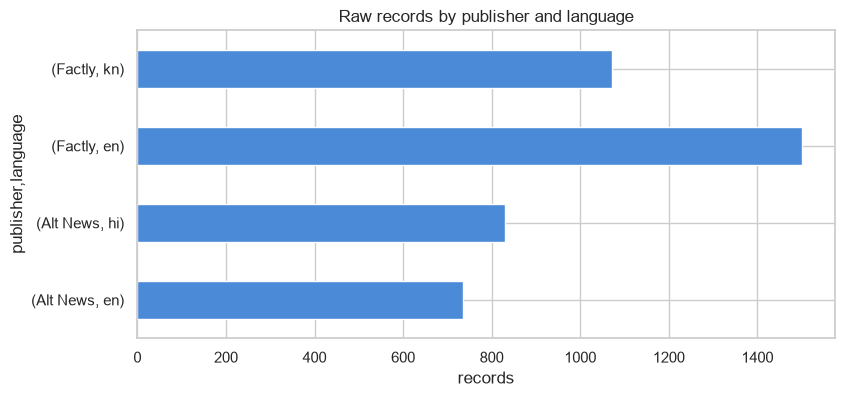

In [6]:
raw = pd.concat([pd.read_json(p, lines=True) for p in sorted(RAW_DIR.glob('*.jsonl'))])
ax = raw.groupby(['publisher','language']).size().plot.barh(color='#4a8ad6'); ax.set_xlabel('records'); ax.set_title('Raw records by publisher and language'); plt.show()

## Observations
* Factly's fact-check categories give a clean stream; every Factly English article contains a `Claim:` block.
* 34% (Hindi) to 41% (English) of Alt News posts were dropped because no verdict rule matched; most are reporting rather than fact-checks.
* Only headlines, the circulating claim and a one-sentence conclusion are stored — never full articles.

**Conclusion.** The pipeline yields ~4.1k attributable Indian fact-checks in three languages without bypassing any access control.